# Neural networks and image filters from arrays

What does a small neural network learn from synthetic images, and when is a simple filter-based explanation already enough?

Proposed 2027; calendar dates pending.


# Neural networks and image filters
Predict first: which local intensity change distinguishes a vertical stripe from a horizontal one? These are original synthetic images, not medical data. The trained model is an MLP; the filter baseline uses fixed coefficients.

In [1]:
import numpy as np
from demo import make_images, kernels, correlate_valid, filter_features
train_images, train_y = make_images(192, 42)
test_images, test_y = make_images(96, 142)
print("Training image shape:", train_images.shape)
print("Filter response shape:", correlate_valid(train_images[:2], kernels()).shape)

Training image shape: (192, 8, 8, 1)
Filter response shape: (2, 6, 6, 2)


Predict the two response signs at opposite sides of an interior bright stripe, then view this saved reference figure. These idealized display images are separate from the training and test data. Both edges remain inside the valid filter window.

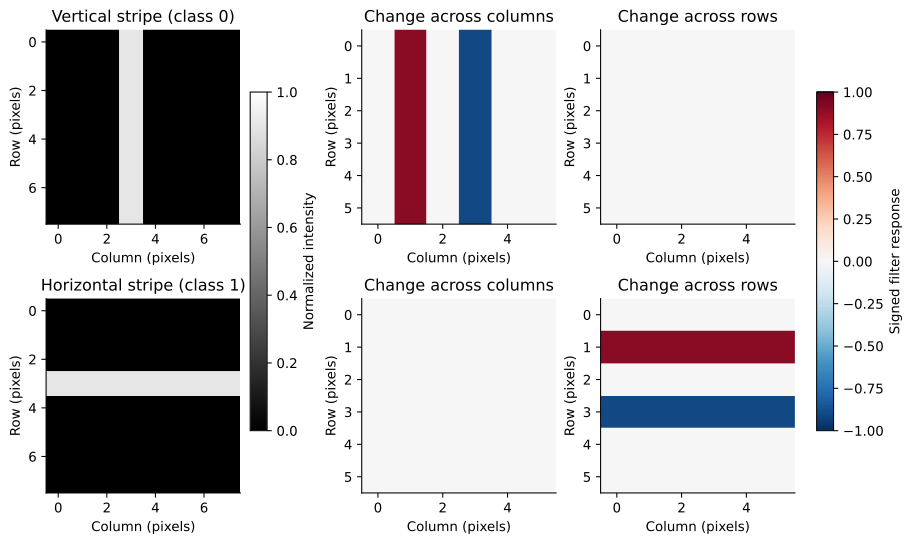

In [2]:
from IPython.display import SVG, display
display(SVG(filename="filters.svg"))

Trace before running: flattened image rows have 64 features. A batch passes through 64→8→1. Fit preprocessing only on training rows. The schedule below is fixed before evaluating the test images.

In [3]:
from demo import train, predict
x_train = train_images.reshape(len(train_images), -1)
x_test = test_images.reshape(len(test_images), -1)
params, mean, scale, history = train(x_train, train_y)
print("Initial/final training loss:", history[0], history[-1])
probability = predict(x_test, params, mean, scale)
print("Held-out MLP accuracy:", np.mean((probability >= 0.5) == test_y))

Initial/final training loss: 0.7101945573661786 0.0040460472598186584
Held-out MLP accuracy: 1.0


Compare: the fixed-filter rule was specified from the image-generation question, not fitted to these test labels. Does the neural model provide an advantage on this task? State the generator and test-set size with any reported score.

In [4]:
features = filter_features(test_images)
fixed_predictions = features[:, 1] > features[:, 0]
print("Fixed-filter accuracy:", np.mean(fixed_predictions == test_y))
print("Constant baseline accuracy:", np.mean(np.zeros(len(test_y)) == test_y))
from demo import gradient_check
print("Maximum checked gradient discrepancy:", gradient_check())

Fixed-filter accuracy: 1.0
Constant baseline accuracy: 0.5
Maximum checked gradient discrepancy: 2.971844992316619e-12


View the saved reference result generated by demo.py with the fixed settings above. This plot repeats the same reference experiment; it is not a second independent test. If you modify training settings in this notebook, compare your printed results with the reference instead of assuming the saved curve has changed.

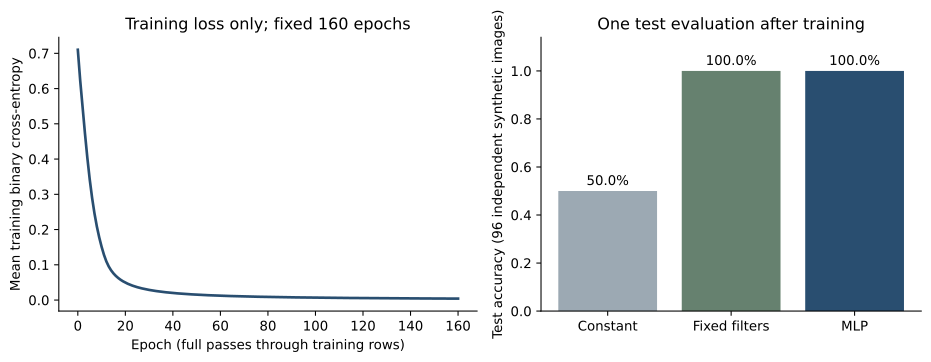

In [5]:
display(SVG(filename="learning-and-baselines.svg"))

Modify and interpret: change one training setting only after stating a prediction. If you use the current test set to choose the setting, it becomes validation data; reserve a fresh independently generated test set before making a final comparison. Optional: trace one 3×3 patch by hand and compare absolute-value pooling with ReLU.